# OffDayOpt
## Constraint-aware evolutionary optimisation for university timetabling

This notebook contains the **entire research implementation**: editable input data, availability domains, fitness, independent validation, repair, five search variants, an exact feasibility model, experiments, visualisations, exports and executable regression tests. No project Python module is imported.

The default benchmark uses supplied module mappings and student weekly-off rules, plus synthetic contact hours, lecturers, rooms and enrolments. It contains 16 cohorts, 18 module codes, 50 offerings and 150 one-hour meetings. CS3 and SE3SQA have user-approved **provisional six-day availability**. DS2A and DS2B inherit Tuesday/Friday off. All classes are Monday–Saturday, 09:30–12:30 and 13:30–15:30.

Choose **Kernel → Restart Kernel and Run All Cells**. The default quick experiment uses a fixed candidate-evaluation budget. The separate reproduction notebook explains the original manuscript's one-second experiments. New results never overwrite `paper_results/`.

All scheduling code is Python. Additional `.py` files in this repository only execute or verify notebooks.

## 1 Environment and experiment configuration
Install dependencies from `requirements.txt` in your notebook kernel before running. No package installation, external API, credentials or network access is performed by this notebook. Dependencies: NumPy, SciPy, pandas, Matplotlib; Jupyter is required for the interactive interface.

`RUN_PROFILE="quick"` runs three seeds with 200 candidate evaluations per algorithm. `"paper"` runs 30 seeds with one second per algorithm. `"custom"` uses the values in `CUSTOM_CONFIG`. Fixed evaluation budgets reproduce assignments and objective values under a compatible Python implementation; elapsed times are never deterministic.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from copy import deepcopy
from dataclasses import dataclass
from html import escape
import csv
import hashlib
import json
import math
import platform
import random
import time
from datetime import datetime, timezone
import unittest
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RUN_PROFILE = "quick"  # quick, paper, custom
CUSTOM_CONFIG = dict(runs=5, budget_mode="evaluations", budget=500, population=24,
                     penalty=100.0, mutation_expected=2.0, random_admission=0.03)
profiles = {
    "quick": dict(CUSTOM_CONFIG, runs=3, budget=200),
    "paper": dict(CUSTOM_CONFIG, runs=30, budget_mode="seconds", budget=1.0),
    "custom": CUSTOM_CONFIG,
}
CONFIG = deepcopy(profiles[RUN_PROFILE])
METHODS = ["random_repair", "ga_penalty", "ga_feasibility", "ga_lamarckian", "ga_baldwinian"]
WEIGHTS = dict(gaps=3, overload=2, same_module_day=1, room_instability=1)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT = ROOT / "outputs" / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
print("Profile:", RUN_PROFILE, "Output:", OUT)
print("Python", platform.python_version(), "NumPy", np.__version__, "SciPy", scipy.__version__)


Profile: quick Output: /workspace/scratch/2a4b04ebc016/offdayopt/outputs/20261018T153821_334635Z
Python 3.12.14 NumPy 2.3.5 SciPy 1.17.0


## 2 Complete editable dataset
The JSON file is the input contract. You can change modules, section calendars, contact-hour events, room capacities or lecturer availability. Each event is exactly one required hour. To add a contact hour, add a uniquely identified event. A two-hour uninterrupted laboratory must **not** be represented as independent hours if contiguity is required; variable-duration/contiguity scheduling is not implemented.

Every availability entry uses `[day_name, zero_based_slot_index]`. An off day removes all five slots. Lecturer and room `unavailable` lists are hard restrictions. Equal module codes across sections share the same assumed lecturer but keep separate events. CSCU9P5 and CSCU9E5 remain distinct. The built-in fallback below is the full dataset, so this notebook also works when downloaded alone.

In [2]:
DEFAULT_INSTANCE = json.loads(r'''
{
  "schema_version": 1,
  "name": "OffDayOpt constructed curriculum benchmark",
  "provenance": {
    "modules": "User supplied",
    "cohort_off_days": "User supplied; DS2 rule inherited by both sections",
    "provisional_calendars": [
      "CS3",
      "SE3SQA"
    ],
    "resources_and_hours": "Synthetic assumptions, not institutional records"
  },
  "calendar": {
    "days": [
      "Monday",
      "Tuesday",
      "Wednesday",
      "Thursday",
      "Friday",
      "Saturday"
    ],
    "day_start": "09:30",
    "day_end": "15:30",
    "breaks": [
      [
        "12:30",
        "13:30"
      ]
    ],
    "slots": [
      [
        "09:30",
        "10:30"
      ],
      [
        "10:30",
        "11:30"
      ],
      [
        "11:30",
        "12:30"
      ],
      [
        "13:30",
        "14:30"
      ],
      [
        "14:30",
        "15:30"
      ]
    ]
  },
  "modules": {
    "CSCU9P1": "Introduction to Computing Science",
    "MATU9S1": "Discrete Structures",
    "MGTU7S1": "The Global Business Environment: An Introduction",
    "CSCU9A3": "Data Structures, Objects and Algorithms",
    "CSCU9B3": "Database Principles and Applications",
    "CSCU9M3": "Scripting for Data Science",
    "CSCU9P5": "Software Engineering I",
    "CSCU9M5": "Introduction to Machine Learning",
    "CSCU9X5": "UX Design",
    "CSCU9Z7": "Computing Science Project",
    "CSCU9Y7": "Computer Security and Networks",
    "CSCU9YW": "Web Services",
    "CSCU9YH": "Mobile App Development",
    "CSCU9P2": "Programming and User Interface Design",
    "CSCU9E5": "Software Engineering I",
    "CSCU9DA": "Data Science Applications",
    "CSCU9YE": "Artificial Intelligence",
    "CSCU9YX": "Cyber Security"
  },
  "cohorts": [
    {
      "id": "CS2",
      "programme": "Computer Science",
      "year": 2,
      "section": "",
      "size": 37,
      "off_days": [
        "Thursday",
        "Saturday"
      ],
      "provisional": false
    },
    {
      "id": "SE1",
      "programme": "Software Engineering",
      "year": 1,
      "section": "",
      "size": 36,
      "off_days": [
        "Wednesday",
        "Friday"
      ],
      "provisional": false
    },
    {
      "id": "DS2A",
      "programme": "Data Science and Artificial Intelligence",
      "year": 2,
      "section": "A",
      "size": 27,
      "off_days": [
        "Tuesday",
        "Friday"
      ],
      "provisional": false
    },
    {
      "id": "DS2B",
      "programme": "Data Science and Artificial Intelligence",
      "year": 2,
      "section": "B",
      "size": 29,
      "off_days": [
        "Tuesday",
        "Friday"
      ],
      "provisional": false
    },
    {
      "id": "SE2A",
      "programme": "Software Engineering",
      "year": 2,
      "section": "A",
      "size": 36,
      "off_days": [
        "Monday",
        "Thursday"
      ],
      "provisional": false
    },
    {
      "id": "SE3B",
      "programme": "Software Engineering",
      "year": 3,
      "section": "B",
      "size": 25,
      "off_days": [
        "Tuesday",
        "Saturday"
      ],
      "provisional": false
    },
    {
      "id": "SE3A",
      "programme": "Software Engineering",
      "year": 3,
      "section": "A",
      "size": 37,
      "off_days": [
        "Tuesday",
        "Thursday"
      ],
      "provisional": false
    },
    {
      "id": "DS3A",
      "programme": "Data Science and Artificial Intelligence",
      "year": 3,
      "section": "A",
      "size": 31,
      "off_days": [
        "Wednesday",
        "Saturday"
      ],
      "provisional": false
    },
    {
      "id": "DS3B",
      "programme": "Data Science and Artificial Intelligence",
      "year": 3,
      "section": "B",
      "size": 32,
      "off_days": [
        "Monday",
        "Tuesday"
      ],
      "provisional": false
    },
    {
      "id": "CS4",
      "programme": "Computer Science",
      "year": 4,
      "section": "",
      "size": 32,
      "off_days": [
        "Thursday",
        "Friday",
        "Saturday"
      ],
      "provisional": false
    },
    {
      "id": "SE4",
      "programme": "Software Engineering",
      "year": 4,
      "section": "",
      "size": 36,
      "off_days": [
        "Thursday",
        "Friday",
        "Saturday"
      ],
      "provisional": false
    },
    {
      "id": "SE2B",
      "programme": "Software Engineering",
      "year": 2,
      "section": "B",
      "size": 25,
      "off_days": [
        "Thursday",
        "Saturday"
      ],
      "provisional": false
    },
    {
      "id": "SE3C",
      "programme": "Software Engineering",
      "year": 3,
      "section": "C",
      "size": 37,
      "off_days": [
        "Thursday",
        "Friday"
      ],
      "provisional": false
    },
    {
      "id": "DS4",
      "programme": "Data Science and Artificial Intelligence",
      "year": 4,
      "section": "",
      "size": 27,
      "off_days": [
        "Tuesday",
        "Wednesday",
        "Friday"
      ],
      "provisional": false
    },
    {
      "id": "CS3",
      "programme": "Computer Science",
      "year": 3,
      "section": "",
      "size": 38,
      "off_days": [],
      "provisional": true
    },
    {
      "id": "SE3SQA",
      "programme": "Software Engineering",
      "year": 3,
      "section": "SQA",
      "size": 24,
      "off_days": [],
      "provisional": true
    }
  ],
  "lecturers": [
    {
      "id": "T01",
      "module_code": "CSCU9A3",
      "unavailable": []
    },
    {
      "id": "T02",
      "module_code": "CSCU9B3",
      "unavailable": []
    },
    {
      "id": "T03",
      "module_code": "CSCU9DA",
      "unavailable": []
    },
    {
      "id": "T04",
      "module_code": "CSCU9E5",
      "unavailable": []
    },
    {
      "id": "T05",
      "module_code": "CSCU9M3",
      "unavailable": []
    },
    {
      "id": "T06",
      "module_code": "CSCU9M5",
      "unavailable": []
    },
    {
      "id": "T07",
      "module_code": "CSCU9P1",
      "unavailable": []
    },
    {
      "id": "T08",
      "module_code": "CSCU9P2",
      "unavailable": []
    },
    {
      "id": "T09",
      "module_code": "CSCU9P5",
      "unavailable": []
    },
    {
      "id": "T10",
      "module_code": "CSCU9X5",
      "unavailable": []
    },
    {
      "id": "T11",
      "module_code": "CSCU9Y7",
      "unavailable": []
    },
    {
      "id": "T12",
      "module_code": "CSCU9YE",
      "unavailable": []
    },
    {
      "id": "T13",
      "module_code": "CSCU9YH",
      "unavailable": []
    },
    {
      "id": "T14",
      "module_code": "CSCU9YW",
      "unavailable": []
    },
    {
      "id": "T15",
      "module_code": "CSCU9YX",
      "unavailable": []
    },
    {
      "id": "T16",
      "module_code": "CSCU9Z7",
      "unavailable": []
    },
    {
      "id": "T17",
      "module_code": "MATU9S1",
      "unavailable": []
    },
    {
      "id": "T18",
      "module_code": "MGTU7S1",
      "unavailable": []
    }
  ],
  "rooms": [
    {
      "id": "R1",
      "type": "Lecture",
      "capacity": 45,
      "unavailable": []
    },
    {
      "id": "R2",
      "type": "Lecture",
      "capacity": 45,
      "unavailable": []
    },
    {
      "id": "R3",
      "type": "Lecture",
      "capacity": 45,
      "unavailable": []
    },
    {
      "id": "R4",
      "type": "Lecture",
      "capacity": 45,
      "unavailable": []
    },
    {
      "id": "R5",
      "type": "Lecture",
      "capacity": 45,
      "unavailable": []
    },
    {
      "id": "LAB1",
      "type": "Lab",
      "capacity": 40,
      "unavailable": []
    },
    {
      "id": "LAB2",
      "type": "Lab",
      "capacity": 40,
      "unavailable": []
    },
    {
      "id": "LAB3",
      "type": "Lab",
      "capacity": 40,
      "unavailable": []
    }
  ],
  "events": [
    {
      "id": "CS2_CSCU9P1_1",
      "cohort": "CS2",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "CS2_CSCU9P1_2",
      "cohort": "CS2",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "CS2_CSCU9P1_3",
      "cohort": "CS2",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lab"
    },
    {
      "id": "CS2_CSCU9P2_1",
      "cohort": "CS2",
      "module": "CSCU9P2",
      "lecturer": "T08",
      "room_type": "Lecture"
    },
    {
      "id": "CS2_CSCU9P2_2",
      "cohort": "CS2",
      "module": "CSCU9P2",
      "lecturer": "T08",
      "room_type": "Lecture"
    },
    {
      "id": "CS2_CSCU9P2_3",
      "cohort": "CS2",
      "module": "CSCU9P2",
      "lecturer": "T08",
      "room_type": "Lab"
    },
    {
      "id": "SE1_CSCU9P1_1",
      "cohort": "SE1",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "SE1_CSCU9P1_2",
      "cohort": "SE1",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "SE1_CSCU9P1_3",
      "cohort": "SE1",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lab"
    },
    {
      "id": "SE1_MATU9S1_1",
      "cohort": "SE1",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "SE1_MATU9S1_2",
      "cohort": "SE1",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "SE1_MATU9S1_3",
      "cohort": "SE1",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "SE1_MGTU7S1_1",
      "cohort": "SE1",
      "module": "MGTU7S1",
      "lecturer": "T18",
      "room_type": "Lecture"
    },
    {
      "id": "SE1_MGTU7S1_2",
      "cohort": "SE1",
      "module": "MGTU7S1",
      "lecturer": "T18",
      "room_type": "Lecture"
    },
    {
      "id": "SE1_MGTU7S1_3",
      "cohort": "SE1",
      "module": "MGTU7S1",
      "lecturer": "T18",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_CSCU9P1_1",
      "cohort": "DS2A",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_CSCU9P1_2",
      "cohort": "DS2A",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_CSCU9P1_3",
      "cohort": "DS2A",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lab"
    },
    {
      "id": "DS2A_MATU9S1_1",
      "cohort": "DS2A",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_MATU9S1_2",
      "cohort": "DS2A",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_MATU9S1_3",
      "cohort": "DS2A",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_CSCU9M3_1",
      "cohort": "DS2A",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_CSCU9M3_2",
      "cohort": "DS2A",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "DS2A_CSCU9M3_3",
      "cohort": "DS2A",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lab"
    },
    {
      "id": "DS2B_CSCU9P1_1",
      "cohort": "DS2B",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "DS2B_CSCU9P1_2",
      "cohort": "DS2B",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lecture"
    },
    {
      "id": "DS2B_CSCU9P1_3",
      "cohort": "DS2B",
      "module": "CSCU9P1",
      "lecturer": "T07",
      "room_type": "Lab"
    },
    {
      "id": "DS2B_MATU9S1_1",
      "cohort": "DS2B",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "DS2B_MATU9S1_2",
      "cohort": "DS2B",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "DS2B_MATU9S1_3",
      "cohort": "DS2B",
      "module": "MATU9S1",
      "lecturer": "T17",
      "room_type": "Lecture"
    },
    {
      "id": "DS2B_CSCU9M3_1",
      "cohort": "DS2B",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "DS2B_CSCU9M3_2",
      "cohort": "DS2B",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "DS2B_CSCU9M3_3",
      "cohort": "DS2B",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lab"
    },
    {
      "id": "SE2A_CSCU9A3_1",
      "cohort": "SE2A",
      "module": "CSCU9A3",
      "lecturer": "T01",
      "room_type": "Lecture"
    },
    {
      "id": "SE2A_CSCU9A3_2",
      "cohort": "SE2A",
      "module": "CSCU9A3",
      "lecturer": "T01",
      "room_type": "Lecture"
    },
    {
      "id": "SE2A_CSCU9A3_3",
      "cohort": "SE2A",
      "module": "CSCU9A3",
      "lecturer": "T01",
      "room_type": "Lab"
    },
    {
      "id": "SE2A_CSCU9B3_1",
      "cohort": "SE2A",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "SE2A_CSCU9B3_2",
      "cohort": "SE2A",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "SE2A_CSCU9B3_3",
      "cohort": "SE2A",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lab"
    },
    {
      "id": "SE2A_CSCU9M3_1",
      "cohort": "SE2A",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "SE2A_CSCU9M3_2",
      "cohort": "SE2A",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "SE2A_CSCU9M3_3",
      "cohort": "SE2A",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lab"
    },
    {
      "id": "SE3B_CSCU9P5_1",
      "cohort": "SE3B",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3B_CSCU9P5_2",
      "cohort": "SE3B",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3B_CSCU9P5_3",
      "cohort": "SE3B",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lab"
    },
    {
      "id": "SE3B_CSCU9M5_1",
      "cohort": "SE3B",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3B_CSCU9M5_2",
      "cohort": "SE3B",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3B_CSCU9M5_3",
      "cohort": "SE3B",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lab"
    },
    {
      "id": "SE3B_CSCU9X5_1",
      "cohort": "SE3B",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3B_CSCU9X5_2",
      "cohort": "SE3B",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3B_CSCU9X5_3",
      "cohort": "SE3B",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lab"
    },
    {
      "id": "SE3A_CSCU9P5_1",
      "cohort": "SE3A",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3A_CSCU9P5_2",
      "cohort": "SE3A",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3A_CSCU9P5_3",
      "cohort": "SE3A",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lab"
    },
    {
      "id": "SE3A_CSCU9M5_1",
      "cohort": "SE3A",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3A_CSCU9M5_2",
      "cohort": "SE3A",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3A_CSCU9M5_3",
      "cohort": "SE3A",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lab"
    },
    {
      "id": "SE3A_CSCU9X5_1",
      "cohort": "SE3A",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3A_CSCU9X5_2",
      "cohort": "SE3A",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3A_CSCU9X5_3",
      "cohort": "SE3A",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lab"
    },
    {
      "id": "DS3A_CSCU9B3_1",
      "cohort": "DS3A",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "DS3A_CSCU9B3_2",
      "cohort": "DS3A",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "DS3A_CSCU9B3_3",
      "cohort": "DS3A",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lab"
    },
    {
      "id": "DS3A_CSCU9M5_1",
      "cohort": "DS3A",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "DS3A_CSCU9M5_2",
      "cohort": "DS3A",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "DS3A_CSCU9M5_3",
      "cohort": "DS3A",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lab"
    },
    {
      "id": "DS3A_CSCU9X5_1",
      "cohort": "DS3A",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "DS3A_CSCU9X5_2",
      "cohort": "DS3A",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "DS3A_CSCU9X5_3",
      "cohort": "DS3A",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lab"
    },
    {
      "id": "DS3B_CSCU9B3_1",
      "cohort": "DS3B",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "DS3B_CSCU9B3_2",
      "cohort": "DS3B",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "DS3B_CSCU9B3_3",
      "cohort": "DS3B",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lab"
    },
    {
      "id": "DS3B_CSCU9M5_1",
      "cohort": "DS3B",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "DS3B_CSCU9M5_2",
      "cohort": "DS3B",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "DS3B_CSCU9M5_3",
      "cohort": "DS3B",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lab"
    },
    {
      "id": "DS3B_CSCU9X5_1",
      "cohort": "DS3B",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "DS3B_CSCU9X5_2",
      "cohort": "DS3B",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "DS3B_CSCU9X5_3",
      "cohort": "DS3B",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lab"
    },
    {
      "id": "CS4_CSCU9Z7_1",
      "cohort": "CS4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9Z7_2",
      "cohort": "CS4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9Z7_3",
      "cohort": "CS4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9Y7_1",
      "cohort": "CS4",
      "module": "CSCU9Y7",
      "lecturer": "T11",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9Y7_2",
      "cohort": "CS4",
      "module": "CSCU9Y7",
      "lecturer": "T11",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9Y7_3",
      "cohort": "CS4",
      "module": "CSCU9Y7",
      "lecturer": "T11",
      "room_type": "Lab"
    },
    {
      "id": "CS4_CSCU9YW_1",
      "cohort": "CS4",
      "module": "CSCU9YW",
      "lecturer": "T14",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9YW_2",
      "cohort": "CS4",
      "module": "CSCU9YW",
      "lecturer": "T14",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9YW_3",
      "cohort": "CS4",
      "module": "CSCU9YW",
      "lecturer": "T14",
      "room_type": "Lab"
    },
    {
      "id": "CS4_CSCU9YH_1",
      "cohort": "CS4",
      "module": "CSCU9YH",
      "lecturer": "T13",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9YH_2",
      "cohort": "CS4",
      "module": "CSCU9YH",
      "lecturer": "T13",
      "room_type": "Lecture"
    },
    {
      "id": "CS4_CSCU9YH_3",
      "cohort": "CS4",
      "module": "CSCU9YH",
      "lecturer": "T13",
      "room_type": "Lab"
    },
    {
      "id": "SE4_CSCU9Z7_1",
      "cohort": "SE4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9Z7_2",
      "cohort": "SE4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9Z7_3",
      "cohort": "SE4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9Y7_1",
      "cohort": "SE4",
      "module": "CSCU9Y7",
      "lecturer": "T11",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9Y7_2",
      "cohort": "SE4",
      "module": "CSCU9Y7",
      "lecturer": "T11",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9Y7_3",
      "cohort": "SE4",
      "module": "CSCU9Y7",
      "lecturer": "T11",
      "room_type": "Lab"
    },
    {
      "id": "SE4_CSCU9YW_1",
      "cohort": "SE4",
      "module": "CSCU9YW",
      "lecturer": "T14",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9YW_2",
      "cohort": "SE4",
      "module": "CSCU9YW",
      "lecturer": "T14",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9YW_3",
      "cohort": "SE4",
      "module": "CSCU9YW",
      "lecturer": "T14",
      "room_type": "Lab"
    },
    {
      "id": "SE4_CSCU9YH_1",
      "cohort": "SE4",
      "module": "CSCU9YH",
      "lecturer": "T13",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9YH_2",
      "cohort": "SE4",
      "module": "CSCU9YH",
      "lecturer": "T13",
      "room_type": "Lecture"
    },
    {
      "id": "SE4_CSCU9YH_3",
      "cohort": "SE4",
      "module": "CSCU9YH",
      "lecturer": "T13",
      "room_type": "Lab"
    },
    {
      "id": "SE2B_CSCU9A3_1",
      "cohort": "SE2B",
      "module": "CSCU9A3",
      "lecturer": "T01",
      "room_type": "Lecture"
    },
    {
      "id": "SE2B_CSCU9A3_2",
      "cohort": "SE2B",
      "module": "CSCU9A3",
      "lecturer": "T01",
      "room_type": "Lecture"
    },
    {
      "id": "SE2B_CSCU9A3_3",
      "cohort": "SE2B",
      "module": "CSCU9A3",
      "lecturer": "T01",
      "room_type": "Lab"
    },
    {
      "id": "SE2B_CSCU9B3_1",
      "cohort": "SE2B",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "SE2B_CSCU9B3_2",
      "cohort": "SE2B",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lecture"
    },
    {
      "id": "SE2B_CSCU9B3_3",
      "cohort": "SE2B",
      "module": "CSCU9B3",
      "lecturer": "T02",
      "room_type": "Lab"
    },
    {
      "id": "SE2B_CSCU9M3_1",
      "cohort": "SE2B",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "SE2B_CSCU9M3_2",
      "cohort": "SE2B",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lecture"
    },
    {
      "id": "SE2B_CSCU9M3_3",
      "cohort": "SE2B",
      "module": "CSCU9M3",
      "lecturer": "T05",
      "room_type": "Lab"
    },
    {
      "id": "SE3C_CSCU9P5_1",
      "cohort": "SE3C",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3C_CSCU9P5_2",
      "cohort": "SE3C",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3C_CSCU9P5_3",
      "cohort": "SE3C",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lab"
    },
    {
      "id": "SE3C_CSCU9M5_1",
      "cohort": "SE3C",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3C_CSCU9M5_2",
      "cohort": "SE3C",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3C_CSCU9M5_3",
      "cohort": "SE3C",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lab"
    },
    {
      "id": "SE3C_CSCU9X5_1",
      "cohort": "SE3C",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3C_CSCU9X5_2",
      "cohort": "SE3C",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3C_CSCU9X5_3",
      "cohort": "SE3C",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lab"
    },
    {
      "id": "DS4_CSCU9Z7_1",
      "cohort": "DS4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9Z7_2",
      "cohort": "DS4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9Z7_3",
      "cohort": "DS4",
      "module": "CSCU9Z7",
      "lecturer": "T16",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9DA_1",
      "cohort": "DS4",
      "module": "CSCU9DA",
      "lecturer": "T03",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9DA_2",
      "cohort": "DS4",
      "module": "CSCU9DA",
      "lecturer": "T03",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9DA_3",
      "cohort": "DS4",
      "module": "CSCU9DA",
      "lecturer": "T03",
      "room_type": "Lab"
    },
    {
      "id": "DS4_CSCU9YE_1",
      "cohort": "DS4",
      "module": "CSCU9YE",
      "lecturer": "T12",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9YE_2",
      "cohort": "DS4",
      "module": "CSCU9YE",
      "lecturer": "T12",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9YE_3",
      "cohort": "DS4",
      "module": "CSCU9YE",
      "lecturer": "T12",
      "room_type": "Lab"
    },
    {
      "id": "DS4_CSCU9YX_1",
      "cohort": "DS4",
      "module": "CSCU9YX",
      "lecturer": "T15",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9YX_2",
      "cohort": "DS4",
      "module": "CSCU9YX",
      "lecturer": "T15",
      "room_type": "Lecture"
    },
    {
      "id": "DS4_CSCU9YX_3",
      "cohort": "DS4",
      "module": "CSCU9YX",
      "lecturer": "T15",
      "room_type": "Lab"
    },
    {
      "id": "CS3_CSCU9E5_1",
      "cohort": "CS3",
      "module": "CSCU9E5",
      "lecturer": "T04",
      "room_type": "Lecture"
    },
    {
      "id": "CS3_CSCU9E5_2",
      "cohort": "CS3",
      "module": "CSCU9E5",
      "lecturer": "T04",
      "room_type": "Lecture"
    },
    {
      "id": "CS3_CSCU9E5_3",
      "cohort": "CS3",
      "module": "CSCU9E5",
      "lecturer": "T04",
      "room_type": "Lab"
    },
    {
      "id": "CS3_CSCU9M5_1",
      "cohort": "CS3",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "CS3_CSCU9M5_2",
      "cohort": "CS3",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "CS3_CSCU9M5_3",
      "cohort": "CS3",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lab"
    },
    {
      "id": "CS3_CSCU9X5_1",
      "cohort": "CS3",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "CS3_CSCU9X5_2",
      "cohort": "CS3",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "CS3_CSCU9X5_3",
      "cohort": "CS3",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lab"
    },
    {
      "id": "SE3SQA_CSCU9P5_1",
      "cohort": "SE3SQA",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3SQA_CSCU9P5_2",
      "cohort": "SE3SQA",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lecture"
    },
    {
      "id": "SE3SQA_CSCU9P5_3",
      "cohort": "SE3SQA",
      "module": "CSCU9P5",
      "lecturer": "T09",
      "room_type": "Lab"
    },
    {
      "id": "SE3SQA_CSCU9M5_1",
      "cohort": "SE3SQA",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3SQA_CSCU9M5_2",
      "cohort": "SE3SQA",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lecture"
    },
    {
      "id": "SE3SQA_CSCU9M5_3",
      "cohort": "SE3SQA",
      "module": "CSCU9M5",
      "lecturer": "T06",
      "room_type": "Lab"
    },
    {
      "id": "SE3SQA_CSCU9X5_1",
      "cohort": "SE3SQA",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3SQA_CSCU9X5_2",
      "cohort": "SE3SQA",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lecture"
    },
    {
      "id": "SE3SQA_CSCU9X5_3",
      "cohort": "SE3SQA",
      "module": "CSCU9X5",
      "lecturer": "T10",
      "room_type": "Lab"
    }
  ]
}
''')
INSTANCE_PATH = ROOT / "data" / "instance.json"
INSTANCE = json.loads(INSTANCE_PATH.read_text(encoding="utf-8")) if INSTANCE_PATH.exists() else deepcopy(DEFAULT_INSTANCE)
print(INSTANCE["name"], "events:", len(INSTANCE["events"]))


OffDayOpt constructed curriculum benchmark events: 150


## 3 Schema validation and legal domains
Malformed input is different from mathematical infeasibility. Schema errors stop execution with a specific message. A valid input may have an empty domain; the solver reports that event as impossible. Legal domains remove weekly-off days, lunch, unavailable resources, unsuitable room types and insufficient seats before evolutionary search.

In [3]:
def minutes(value):
    if not isinstance(value, str):
        raise ValueError("Time must be HH:MM text")
    parts = value.split(":")
    if len(parts) != 2 or any(len(p) != 2 or not p.isdigit() for p in parts):
        raise ValueError(f"Invalid HH:MM time: {value}")
    h, m = map(int, parts)
    if not 0 <= h < 24 or not 0 <= m < 60:
        raise ValueError(f"Invalid time: {value}")
    return 60*h + m


def check_schema(data):
    if data.get("schema_version") != 1:
        raise ValueError("schema_version must be 1")
    cal = data["calendar"]
    days, slots = cal["days"], cal["slots"]
    if not days or len(set(days)) != len(days) or not all(isinstance(d, str) for d in days):
        raise ValueError("Calendar days must be unique names")
    if not slots:
        raise ValueError("At least one teaching slot is required")
    start, end = minutes(cal["day_start"]), minutes(cal["day_end"])
    if start >= end:
        raise ValueError("day_start must precede day_end")
    breaks = [(minutes(a), minutes(b)) for a,b in cal.get("breaks", [])]
    if any(not start <= a < b <= end for a,b in breaks):
        raise ValueError("Breaks must lie within the teaching day")
    previous = start
    for a,b in slots:
        a,b = minutes(a), minutes(b)
        if not start <= a < b <= end or b-a != 60 or a < previous:
            raise ValueError("Teaching slots must be ordered nonoverlapping one-hour intervals")
        if any(a < v and b > u for u,v in breaks):
            raise ValueError("Teaching slot overlaps a protected break")
        previous = b
    indexes = {}
    for name in ["cohorts", "lecturers", "rooms", "events"]:
        items = data[name]
        if not items:
            raise ValueError(f"{name} must not be empty")
        ids = [v["id"] for v in items]
        if not all(isinstance(i,str) and i for i in ids) or len(ids) != len(set(ids)):
            raise ValueError(f"Duplicate or invalid identifier in {name}")
        indexes[name] = {v["id"]:v for v in items}
    for g in data["cohorts"]:
        if type(g["size"]) is not int or g["size"] <= 0:
            raise ValueError("Cohort sizes must be positive integers")
        if not set(g.get("off_days",[])) <= set(days):
            raise ValueError(f"Unknown off day for {g['id']}")
    for r in data["rooms"]:
        if type(r["capacity"]) is not int or r["capacity"] <= 0:
            raise ValueError("Room capacities must be positive integers")
    for name in ["rooms", "lecturers"]:
        for item in data[name]:
            for day, slot in item.get("unavailable", []):
                if day not in days or type(slot) is not int or not 0 <= slot < len(slots):
                    raise ValueError(f"Invalid availability entry for {item['id']}")
    for e in data["events"]:
        if e["cohort"] not in indexes["cohorts"] or e["lecturer"] not in indexes["lecturers"]:
            raise ValueError(f"Unknown cohort/lecturer in {e['id']}")
        if e["module"] not in data["modules"]:
            raise ValueError(f"Unknown module in {e['id']}")
    return indexes


def build_domains(data):
    ix = check_schema(data)
    cal = data["calendar"]; days = cal["days"]; P = len(cal["slots"])
    domains = []
    for e in data["events"]:
        g = ix["cohorts"][e["cohort"]]
        lecturer = ix["lecturers"][e["lecturer"]]
        allowed = []
        for day_index, day in enumerate(days):
            if day in g.get("off_days", []):
                continue
            for slot in range(P):
                if [day,slot] in lecturer.get("unavailable",[]):
                    continue
                for room_index, room in enumerate(data["rooms"]):
                    if room["type"] == e["room_type"] and room["capacity"] >= g["size"] and [day,slot] not in room.get("unavailable",[]):
                        allowed.append((day_index*P+slot, room_index))
        domains.append(tuple(allowed))
    return domains

INDEX = check_schema(INSTANCE)
DOMAINS = build_domains(INSTANCE)
print("Legal placement counts:", min(map(len,DOMAINS)), "to", max(map(len,DOMAINS)))


Legal placement counts: 45 to 150


## 4 Exploratory analysis and necessary capacity checks
Capacity bounds identify some impossible workloads without search. Passing a bound is **not** proof of feasibility; coupled lecturer and room conflicts can still prevent a solution. Hours are meeting counts because every event is one hour. Room occupancy means occupied room-periods, not occupied seats.

cohort  available_hours  contact_hours  slack  synthetic_students  provisional
   CS2               20              6     14                  37        False
   SE1               20              9     11                  36        False
  DS2A               20              9     11                  27        False
  DS2B               20              9     11                  29        False
  SE2A               20              9     11                  36        False
  SE3B               20              9     11                  25        False
  SE3A               20              9     11                  37        False
  DS3A               20              9     11                  31        False
  DS3B               20              9     11                  32        False
   CS4               15             12      3                  32        False
   SE4               15             12      3                  36        False
  SE2B               20              9     11       

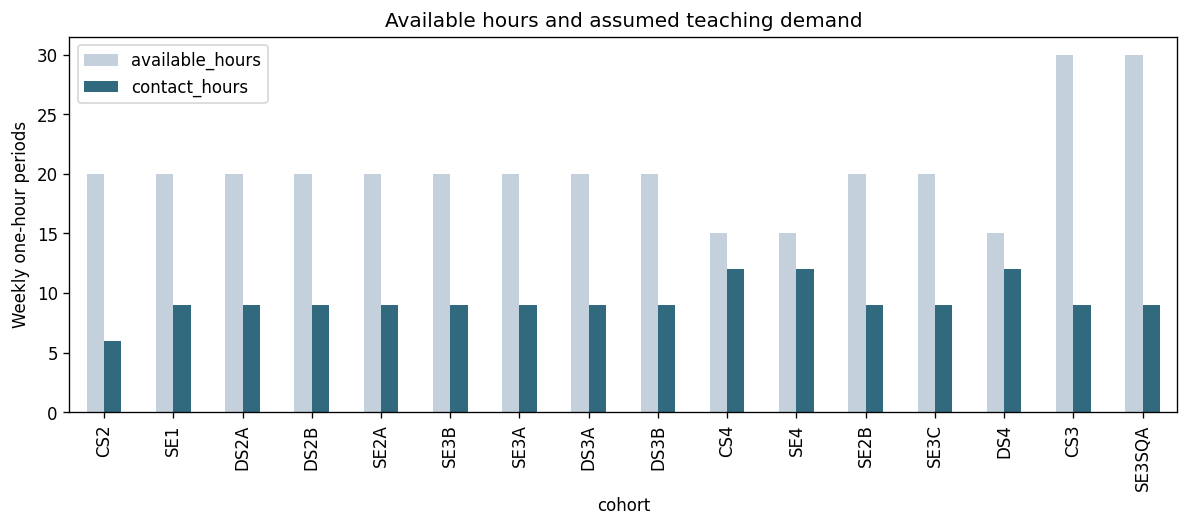

In [4]:
def capacity_analysis(data):
    P = len(data["calendar"]["slots"]); D = len(data["calendar"]["days"])
    demand = Counter(e["cohort"] for e in data["events"])
    rows = []
    for g in data["cohorts"]:
        available = (D-len(set(g.get("off_days",[]))))*P
        rows.append(dict(cohort=g["id"], available_hours=available,
                         contact_hours=demand[g["id"]], slack=available-demand[g["id"]],
                         synthetic_students=g["size"], provisional=g.get("provisional",False)))
    return pd.DataFrame(rows)

CAPACITY = capacity_analysis(INSTANCE)
print(CAPACITY.to_string(index=False))
print("Module offerings:", len(set((e["cohort"],e["module"]) for e in INSTANCE["events"])))
print("Meetings:", Counter(e["room_type"] for e in INSTANCE["events"]))
print("Students:", sum(g["size"] for g in INSTANCE["cohorts"]))
fig, ax = plt.subplots(figsize=(10,4.5))
CAPACITY.set_index("cohort")[["available_hours","contact_hours"]].plot.bar(ax=ax, color=["#c4d1dc","#31697f"])
ax.set_ylabel("Weekly one-hour periods"); ax.set_title("Available hours and assumed teaching demand")
fig.tight_layout(); fig.savefig(OUT/"capacity.png",dpi=180); plt.show()
CAPACITY.to_csv(OUT/"capacity.csv",index=False)


## 5 Independent output validator
The validator does not trust fitness or repair. Assignments are event-ID dictionaries, so duplicate, missing and unknown events can be reported explicitly. It checks bounds before indexing and rejects negative room indices, malformed placements, cohort off days, lecturer/room unavailability, room type, seat capacity and resource clashes. An invalid candidate is never presented as a valid timetable.

In [5]:
def records_from_vector(data, vector):
    if len(vector) != len(data["events"]):
        raise ValueError("Assignment length differs from event count")
    return [dict(event=e["id"], time=t, room=r) for e,(t,r) in zip(data["events"],vector)]


def validate_records(data, records):
    ix = check_schema(data)
    faults = []
    counts = Counter()
    seen = {"cohort": {}, "lecturer": {}, "room": {}}
    P = len(data["calendar"]["slots"]); days = data["calendar"]["days"]
    def fail(kind, event):
        faults.append(dict(kind=kind,event=str(event)))
    if not isinstance(records,list):
        return dict(valid=False,fault_counts={"malformed_records":1},faults=[],expected=len(data["events"]))
    for rec in records:
        if not isinstance(rec,dict):
            fail("malformed_record",None); continue
        event_id = rec.get("event")
        if not isinstance(event_id,str) or event_id not in ix["events"]:
            fail("unknown_event",event_id); continue
        counts[event_id] += 1
        if counts[event_id] > 1:
            fail("duplicate_event",event_id)
        e = ix["events"][event_id]; t = rec.get("time"); r = rec.get("room")
        if type(t) is not int or not 0 <= t < len(days)*P:
            fail("time_bounds",event_id); continue
        if type(r) is not int or not 0 <= r < len(data["rooms"]):
            fail("room_bounds",event_id); continue
        day, slot = days[t//P], t%P
        g = ix["cohorts"][e["cohort"]]; lecturer = ix["lecturers"][e["lecturer"]]; room = data["rooms"][r]
        if day in g.get("off_days",[]):fail("weekly_off",event_id)
        if [day,slot] in lecturer.get("unavailable",[]):fail("lecturer_unavailable",event_id)
        if [day,slot] in room.get("unavailable",[]):fail("room_unavailable",event_id)
        if room["type"] != e["room_type"]:fail("room_type",event_id)
        if room["capacity"] < g["size"]:fail("room_capacity",event_id)
        for resource,key in [("cohort",e["cohort"]),("lecturer",e["lecturer"]),("room",r)]:
            if (key,t) in seen[resource]:fail(resource+"_clash",event_id)
            seen[resource][key,t] = event_id
    for e in data["events"]:
        if not counts[e["id"]]:fail("missing_event",e["id"])
    return dict(valid=not faults, fault_counts=dict(Counter(f["kind"] for f in faults)),
                faults=faults, expected=len(data["events"]), received=len(records))


## 6 Fitness and scarcity-guided repair
Hard conflict count H is the number of cohort, lecturer and room **pairs** occupying the same period. Legal domains already enforce other hard requirements. Soft score is S = 3G + 2O + M + R: avoidable cohort gaps, hours above four per cohort-day, repeated module meetings on the same day, and distinct rooms above two per cohort-module. Lunch is excluded from the gap index. These weights are experimental assumptions.

Repair processes scarce placement domains first, with random tie ordering. It first attempts an inherited placement, then other legal assignments. It may fail if coordinated swaps are needed, and its failure is retained in the outcome. Baldwinian repair evaluates a temporary phenotype; Lamarckian repair writes that phenotype into the genotype.

In [6]:
def evaluate(data, vector, weights=None):
    weights = WEIGHTS if weights is None else weights
    if len(vector) != len(data["events"]):
        raise ValueError("Wrong assignment length")
    P = len(data["calendar"]["slots"])
    gc, lc, rc = Counter(), Counter(), Counter()
    used, module_days, module_rooms = defaultdict(list), Counter(), defaultdict(set)
    for e,(t,r) in zip(data["events"],vector):
        gc[e["cohort"],t]+=1; lc[e["lecturer"],t]+=1; rc[r,t]+=1
        used[e["cohort"],t//P].append(t%P)
        module_days[e["cohort"],e["module"],t//P]+=1
        module_rooms[e["cohort"],e["module"]].add(r)
    hard=sum(v*(v-1)//2 for c in [gc,lc,rc] for v in c.values())
    detail=dict(gaps=sum(max(ps)-min(ps)+1-len(set(ps)) for ps in used.values()),
                overload=sum(max(0,len(ps)-4) for ps in used.values()),
                same_module_day=sum(max(0,v-1) for v in module_days.values()),
                room_instability=sum(max(0,len(rs)-2) for rs in module_rooms.values()))
    return hard, sum(weights[k]*v for k,v in detail.items()), detail


def repair(data, vector, domains, rng):
    order=list(range(len(vector))); rng.shuffle(order); order.sort(key=lambda i:len(domains[i]))
    result=list(vector); gc,lc,rc=set(),set(),set(); probes=0
    for i in order:
        e=data["events"][i]
        # Legal genes are required; no unrestricted fallback can introduce an off-day placement.
        if vector[i] not in domains[i]:raise ValueError("Repair received an illegal gene")
        candidates=[vector[i]]+rng.sample(list(domains[i]),len(domains[i]))
        placement=vector[i]
        for t,r in candidates:
            probes+=1
            if (e["cohort"],t) not in gc and (e["lecturer"],t) not in lc and (r,t) not in rc:
                placement=(t,r); break
        t,r=placement; result[i]=placement
        gc.add((e["cohort"],t));lc.add((e["lecturer"],t));rc.add((r,t))
    return result,probes


## 7 Five search variants and reproducible budgets
The four manuscript variants are retained, with an additional **feasibility-first GA without repair** ablation. Candidate evaluation budgets count complete fitness evaluations, not equivalent primitive work. Repair resource probes are reported separately. Wall-clock budgets include initialisation, but the initial population is always completed, so budgets are soft.

All variants share the same initial portfolio for a seed. They then receive separate random streams. Every archive retains the evaluated phenotype, including Baldwinian candidates. The static penalty population uses λH+S; all other populations use (H,S). A separate archive always uses (H,S), as in the manuscript. New implementation results need not numerically reproduce the legacy timed study.

In [7]:
def run_search(data, method="ga_lamarckian", seed=0, config=None):
    cfg=deepcopy(CONFIG if config is None else config)
    if method not in METHODS:raise ValueError("Unknown method: "+method)
    n_pop=cfg["population"]
    if type(n_pop) is not int or n_pop<2:raise ValueError("population must be an integer >=2")
    if cfg["budget_mode"] not in ["seconds","evaluations"]:raise ValueError("Unknown budget mode")
    if cfg["budget"]<=0:raise ValueError("budget must be positive")
    if cfg["budget_mode"]=="evaluations" and (type(cfg["budget"]) is not int or cfg["budget"]<n_pop):
        raise ValueError("Evaluation budget must be an integer at least population size")
    if not 0<=cfg["random_admission"]<=1 or cfg["penalty"]<0 or cfg["mutation_expected"]<0:
        raise ValueError("Invalid search parameters")
    domains=build_domains(data); empty=[e["id"] for e,d in zip(data["events"],domains) if not d]
    if empty:raise ValueError("No legal placement for: "+", ".join(empty))
    begin=time.perf_counter();n=len(data["events"])
    initial_rng=random.Random(seed)
    initial=[[initial_rng.choice(dom) for dom in domains] for _ in range(n_pop)]
    rng=random.Random(seed+1000003*(METHODS.index(method)+1))
    population=[]; best=None; best_vector=None; count=0; probes=0; trace=[]; first=None
    def score(genotype):
        nonlocal best,best_vector,count,probes,first
        if method in ["random_repair","ga_lamarckian","ga_baldwinian"]:
            phenotype,pr=repair(data,genotype,domains,rng);probes+=pr
        else:phenotype=list(genotype)
        hard,soft,detail=evaluate(data,phenotype);count+=1
        actual=(hard,soft)
        if best is None or actual<best:
            best=actual;best_vector=list(phenotype)
            trace.append(dict(evaluations=count,seconds=time.perf_counter()-begin,hard=hard,soft=soft))
            if hard==0 and first is None:first=time.perf_counter()-begin
        rank=(cfg["penalty"]*hard+soft,) if method=="ga_penalty" else actual
        stored=list(phenotype if method=="ga_lamarckian" else genotype)
        return rank,stored
    for genotype in initial:population.append(score(genotype))
    def within_budget():
        return count<cfg["budget"] if cfg["budget_mode"]=="evaluations" else time.perf_counter()-begin<cfg["budget"]
    while within_budget():
        if method=="random_repair":
            score([rng.choice(dom) for dom in domains]);continue
        def tournament():return min(rng.sample(population,2),key=lambda z:z[0])[1]
        a,b=tournament(),tournament()
        child=[a[i] if rng.random()<.5 else b[i] for i in range(n)]
        for i in range(n):
            if rng.random()<min(1,cfg["mutation_expected"]/n):child[i]=rng.choice(domains[i])
        candidate=score(child);worst=max(range(n_pop),key=lambda i:population[i][0])
        if candidate[0]<population[worst][0]:population[worst]=candidate
        elif rng.random()<cfg["random_admission"]:population[rng.randrange(n_pop)]=candidate
    elapsed=time.perf_counter()-begin
    hard,soft,detail=evaluate(data,best_vector)
    validation=validate_records(data,records_from_vector(data,best_vector))
    if hard==0 and not validation["valid"]:raise RuntimeError("Fitness/validator disagreement")
    return dict(method=method,seed=seed,hard=hard,soft=soft,feasible=validation["valid"],
                elapsed=elapsed,evaluations=count,repair_probes=probes,
                first_feasible_seconds=first,budget_mode=cfg["budget_mode"],budget=cfg["budget"],
                components=detail,assignment=best_vector,validation=validation,trace=trace)


## 8 Exact feasibility baseline with heterogeneous rooms
The zero-objective binary MILP includes one variable per **legal event-time-room assignment**. Cohort, lecturer and room-period constraints are explicit. Unlike the original aggregate model, this implementation supports heterogeneous seats and resource unavailability. Solver status and validated incumbents are reported separately. A time-limit result is never called infeasible without proof. No soft-score optimality is claimed.

In [8]:
def solve_exact(data, seconds=10.0):
    if seconds<=0:raise ValueError("Exact solver time limit must be positive")
    domains=build_domains(data);begin=time.perf_counter()
    empty=[e["id"] for e,d in zip(data["events"],domains) if not d]
    if empty:return dict(status="infeasible_empty_domain",feasible=False,empty_events=empty,assignment=None)
    variables=[(i,t,r) for i,dom in enumerate(domains) for t,r in dom]
    rows=defaultdict(list)
    for j,(i,t,r) in enumerate(variables):
        e=data["events"][i]
        for key in [("event",i),("cohort",e["cohort"],t),("lecturer",e["lecturer"],t),("room",r,t)]:
            rows[key].append(j)
    rr=[];cc=[];lower=[];upper=[]
    for k,(key,cols) in enumerate(rows.items()):
        rr.extend([k]*len(cols));cc.extend(cols);lower.append(1 if key[0]=="event" else 0);upper.append(1)
    A=coo_matrix((np.ones(len(rr)),(rr,cc)),shape=(len(rows),len(variables))).tocsc()
    sol=milp(np.zeros(len(variables)),integrality=np.ones(len(variables)),bounds=Bounds(0,1),
             constraints=LinearConstraint(A,lower,upper),options={"time_limit":float(seconds)})
    vector=None; validation=None
    if sol.x is not None:
        vector=[None]*len(data["events"])
        for (i,t,r),value in zip(variables,sol.x):
            if value>.5:
                if vector[i] is not None:raise RuntimeError("Exact solution assigned event twice")
                vector[i]=(t,r)
        if any(v is None for v in vector):vector=None
        if vector is not None:
            validation=validate_records(data,records_from_vector(data,vector))
            if not validation["valid"]:raise RuntimeError("Exact incumbent failed independent validation")
    feasible=vector is not None
    status="feasible" if feasible else ("infeasible" if sol.status==2 else "unknown")
    return dict(status=status,solver_status=int(sol.status),message=sol.message,feasible=feasible,
                assignment=vector,validation=validation,variables=len(variables),constraints=len(rows),
                elapsed=time.perf_counter()-begin,objective="zero feasibility only",
                soft_score=evaluate(data,vector)[1] if feasible else None)

EXACT = solve_exact(INSTANCE, seconds=10)
print({k:v for k,v in EXACT.items() if k not in ["assignment","validation"]})


{'status': 'feasible', 'solver_status': 0, 'message': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)', 'feasible': True, 'variables': 13250, 'constraints': 1130, 'elapsed': 3.2190721010001653, 'objective': 'zero feasibility only', 'soft_score': 189}


## 9 Execute the stochastic experiment
The execution order is independently shuffled per seed to reduce fixed-order timing bias. This is an enhancement over the manuscript's original fixed order. Each complete run, including failures, is written to JSON and CSV; all final assignments and improvement traces are retained. Dataset and configuration hashes bind results to their inputs.

In [9]:
RESULTS=[]
for seed in range(CONFIG["runs"]):
    order=list(METHODS);random.Random(900000+seed).shuffle(order)
    for method in order:
        outcome=run_search(INSTANCE,method,seed,CONFIG)
        RESULTS.append(outcome)
    print("Completed seed",seed)

rows=[]
for z in RESULTS:
    rows.append({**{k:z[k] for k in ["method","seed","hard","soft","feasible","elapsed","evaluations","repair_probes","first_feasible_seconds","budget_mode","budget"]},**z["components"]})
RUNS=pd.DataFrame(rows)
RUNS.to_csv(OUT/"runs.csv",index=False)
(OUT/"all_runs.json").write_text(json.dumps(RESULTS,indent=2))
(OUT/"exact_feasibility.json").write_text(json.dumps(EXACT,indent=2))
(OUT/"instance.json").write_text(json.dumps(INSTANCE,indent=2))
(OUT/"provenance.json").write_text(json.dumps(dict(config=CONFIG,weights=WEIGHTS,
    instance_sha256=hashlib.sha256(json.dumps(INSTANCE,sort_keys=True).encode()).hexdigest(),
    python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,
    study="new notebook execution; not the frozen manuscript study"),indent=2))
print(RUNS.groupby("method")[["hard","soft","evaluations","repair_probes"]].median())


Completed seed 0
Completed seed 1
Completed seed 2
                hard   soft  evaluations  repair_probes
method                                                 
ga_baldwinian    0.0  160.0        200.0        89404.0
ga_feasibility  56.0  214.0        200.0            0.0
ga_lamarckian    0.0  146.0        200.0        73782.0
ga_penalty      69.0  185.0        200.0            0.0
random_repair    0.0  150.0        200.0        90095.0


## 10 Conditional analysis and honest uncertainty
Success rate always uses all runs. Soft quality is summarised only for feasible runs and labelled with its sample count. With fewer than five feasible outcomes, no bootstrap interval is produced. Intervals are conditional on the one workload and do not quantify generalisation to other institutions. No Friedman test is performed across seeds of a single instance.

        method  runs  feasible_runs  success_rate  median_hard  median_soft    q1    q3 median_ci_low median_ci_high  median_evaluations  success_ci_low  success_ci_high
 ga_baldwinian     3              3           1.0          0.0        160.0 152.0 163.5          None           None               200.0    4.385030e-01         1.000000
ga_feasibility     3              0           0.0         56.0          NaN   NaN   NaN          None           None               200.0    5.551115e-17         0.561497
 ga_lamarckian     3              3           1.0          0.0        146.0 146.0 148.5          None           None               200.0    4.385030e-01         1.000000
    ga_penalty     3              0           0.0         69.0          NaN   NaN   NaN          None           None               200.0    5.551115e-17         0.561497
 random_repair     3              3           1.0          0.0        150.0 149.0 156.0          None           None               200.0    4.385030e-

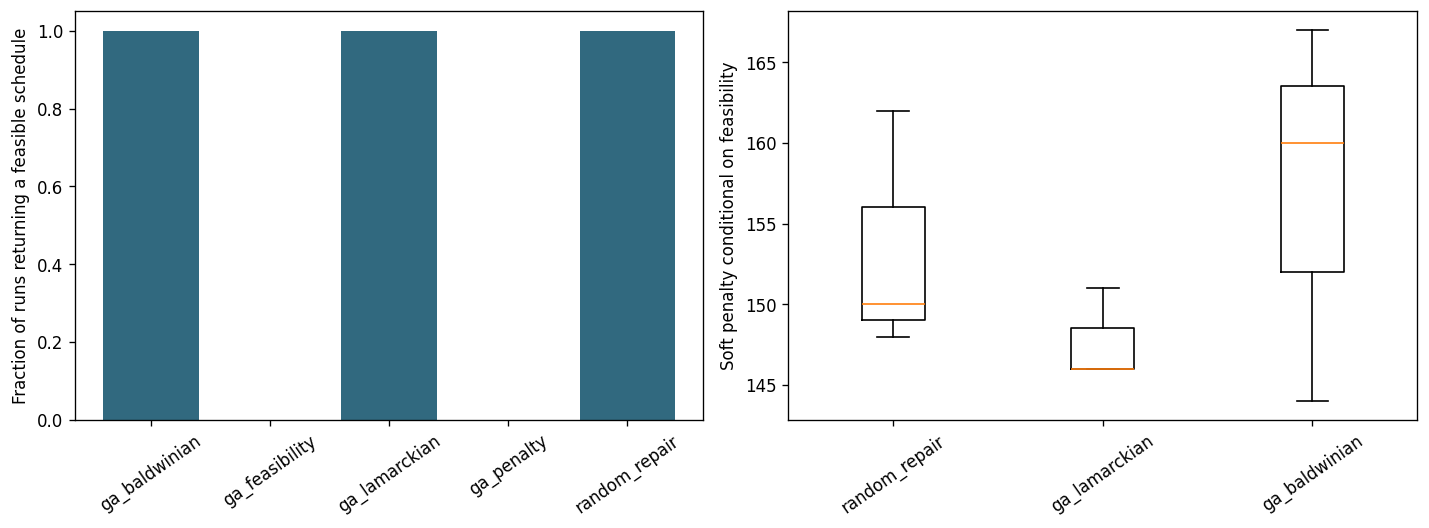

In [10]:
def summarise_runs(frame, resamples=2000):
    rng=np.random.default_rng(20261018);summary=[]
    for method,z in frame.groupby("method",sort=True):
        ok=z[z.feasible.astype(bool)];n=len(z);k=len(ok)
        item=dict(method=method,runs=n,feasible_runs=k,success_rate=k/n,
                  median_hard=float(z.hard.median()),median_soft=None,q1=None,q3=None,
                  median_ci_low=None,median_ci_high=None,median_evaluations=float(z.evaluations.median()))
        # Wilson interval for conditional run success.
        z95=1.959963984540054;den=1+z95*z95/n;p=k/n
        center=(p+z95*z95/(2*n))/den
        half=z95*math.sqrt(p*(1-p)/n+z95*z95/(4*n*n))/den
        item.update(success_ci_low=max(0,center-half),success_ci_high=min(1,center+half))
        if k:
            a=ok.soft.to_numpy();item.update(median_soft=float(np.median(a)),q1=float(np.quantile(a,.25)),q3=float(np.quantile(a,.75)))
            if k>=5:
                b=np.median(rng.choice(a,(resamples,k),replace=True),axis=1)
                item.update(median_ci_low=float(np.quantile(b,.025)),median_ci_high=float(np.quantile(b,.975)))
        summary.append(item)
    return pd.DataFrame(summary)

SUMMARY=summarise_runs(RUNS)
SUMMARY.to_csv(OUT/"summary.csv",index=False)
print(SUMMARY.to_string(index=False))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].bar(SUMMARY.method,SUMMARY.success_rate,color="#31697f")
axes[0].set_ylim(0,1.05);axes[0].set_ylabel("Fraction of runs returning a feasible schedule")
valid_methods=[m for m in METHODS if len(RUNS[(RUNS.method==m)&RUNS.feasible])]
if valid_methods:
    axes[1].boxplot([RUNS[(RUNS.method==m)&RUNS.feasible].soft for m in valid_methods],tick_labels=valid_methods)
axes[1].set_ylabel("Soft penalty conditional on feasibility")
for ax in axes:ax.tick_params(axis="x",rotation=35)
fig.tight_layout();fig.savefig(OUT/"comparison.png",dpi=180);plt.show()


## 11 Select a validated schedule and export cohort timetables
The best feasible stochastic outcome is used for the example timetable. If none succeeded, a validated exact feasibility witness is used and explicitly labelled as such; failed stochastic runs remain failures in the analysis. If both routes fail, no ordinary timetable is exported. HTML output escapes data labels and remains a local static report.

In [11]:
def timetable_frame(data, vector):
    cal=data["calendar"];P=len(cal["slots"]);rows=[]
    for e,(t,r) in zip(data["events"],vector):
        a,b=cal["slots"][t%P]
        rows.append(dict(event=e["id"],cohort=e["cohort"],module=e["module"],
                         module_name=data["modules"][e["module"]],lecturer=e["lecturer"],
                         room=data["rooms"][r]["id"],day=cal["days"][t//P],
                         slot=t%P,time=a+"–"+b,day_index=t//P))
    return pd.DataFrame(rows).sort_values(["day_index","slot","room"])


def export_html(data, vector, path, source):
    report=validate_records(data,records_from_vector(data,vector))
    if not report["valid"]:raise ValueError("Cannot export an invalid timetable")
    frame=timetable_frame(data,vector);cal=data["calendar"]
    parts=['<!doctype html><html><meta charset="utf-8"><title>OffDayOpt timetable</title>',
           '<style>body{font:15px Arial;margin:30px;color:#183143}table{border-collapse:collapse;width:100%;margin-bottom:28px}td,th{border:1px solid #ccd4da;padding:9px}th{background:#e9eff4}.off{background:#eee}</style>',
           '<h1>OffDayOpt validated research timetable</h1><p>Source: '+escape(source)+'. Contact hours and resources are assumptions. CS3 and SE3SQA calendars are provisional. Protected breaks: '+escape(str(cal.get("breaks",[])))+'</p>']
    for g in data["cohorts"]:
        parts.append('<h2>'+escape(g["id"])+'</h2><table><tr><th>Day</th>'+''.join('<th>'+escape(a+'–'+b)+'</th>' for a,b in cal["slots"])+'</tr>')
        for day in cal["days"]:
            parts.append('<tr><th>'+escape(day)+'</th>')
            for slot in range(len(cal["slots"])):
                z=frame[(frame.cohort==g["id"])&(frame.day==day)&(frame.slot==slot)]
                text='OFF' if day in g.get("off_days",[]) else ('Free' if z.empty else str(z.iloc[0]["module"])+" / "+str(z.iloc[0]["room"])+" / "+str(z.iloc[0]["lecturer"]))
                parts.append('<td>'+escape(text)+'</td>')
            parts.append('</tr>')
        parts.append('</table>')
    parts.append('</html>');Path(path).write_text(''.join(parts),encoding='utf-8')

feasible=[z for z in RESULTS if z["feasible"]]
if feasible:
    selected=min(feasible,key=lambda z:z["soft"])
    SELECTED=selected["assignment"];SELECTED_SOURCE=selected["method"]+" seed "+str(selected["seed"])
elif EXACT["feasible"]:
    SELECTED=EXACT["assignment"];SELECTED_SOURCE="Exact feasibility fallback; no stochastic run succeeded"
else:
    SELECTED=None;SELECTED_SOURCE="No validated timetable found"
print(SELECTED_SOURCE)
if SELECTED is not None:
    VALIDATION=validate_records(INSTANCE,records_from_vector(INSTANCE,SELECTED))
    print("Validation:",VALIDATION["valid"],"Score:",evaluate(INSTANCE,SELECTED))
    timetable_frame(INSTANCE,SELECTED).to_csv(OUT/"timetable.csv",index=False)
    (OUT/"selected_assignment.json").write_text(json.dumps(records_from_vector(INSTANCE,SELECTED),indent=2))
    (OUT/"validation.json").write_text(json.dumps(VALIDATION,indent=2))
    export_html(INSTANCE,SELECTED,OUT/"timetable.html",SELECTED_SOURCE)


ga_baldwinian seed 1
Validation: True Score: (0, 144, {'gaps': 26, 'overload': 2, 'same_module_day': 24, 'room_instability': 38})


## 12 Visualise cohort calendars and actual teaching loads
OFF is a hard calendar rule; a zero on an available day means the generated timetable has no class that day. A timetable need not occupy every available day. The display is based on the actual selected assignment, not a fabricated illustration.

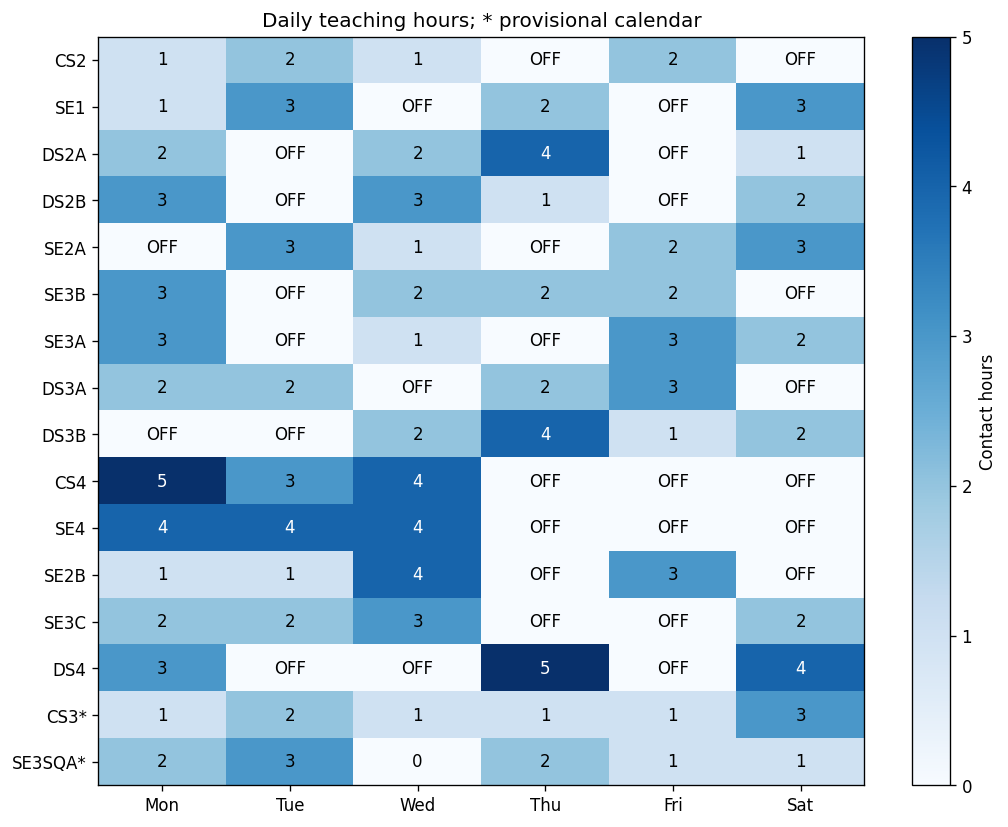

In [12]:
cal=INSTANCE["calendar"];days=cal["days"];P=len(cal["slots"])
loads=np.zeros((len(INSTANCE["cohorts"]),len(days)),int)
if SELECTED is not None:
    gi={g["id"]:i for i,g in enumerate(INSTANCE["cohorts"])}
    for e,(t,r) in zip(INSTANCE["events"],SELECTED):loads[gi[e["cohort"]],t//P]+=1
    fig,ax=plt.subplots(figsize=(9,7))
    image=ax.imshow(loads,cmap="Blues",vmin=0,vmax=P,aspect="auto")
    ax.set_xticks(range(len(days)),[d[:3] for d in days])
    ax.set_yticks(range(len(INSTANCE["cohorts"])),[g["id"]+('*' if g.get("provisional") else '') for g in INSTANCE["cohorts"]])
    for i,g in enumerate(INSTANCE["cohorts"]):
        for d,day in enumerate(days):
            ax.text(d,i,"OFF" if day in g.get("off_days",[]) else str(loads[i,d]),ha="center",va="center",color="white" if loads[i,d]>=4 else "black")
    ax.set_title("Daily teaching hours; * provisional calendar")
    fig.colorbar(image,ax=ax,label="Contact hours");fig.tight_layout()
    fig.savefig(OUT/"daily_load.png",dpi=180);plt.show()


## 13 Resource sensitivity and minimum-room certificate
Under fixed exclusive room types, event counts imply necessary room-count bounds: ceil(type demand / weekly periods). Heterogeneous room capacity, unavailability or specialised equipment may strengthen the bound. A feasible validated witness at the bound proves sufficiency for that dataset. Failure to find a witness before a time limit does not prove insufficiency.

For the default data, 107 lecture and 43 laboratory meetings imply at least four lecture rooms and two labs. Scenarios remove rooms from the supplied inventory without changing meetings, weekly offs or cohort sizes. This notebook computes the status afresh and exports each feasible witness.

In [13]:
def room_scenario(data, lecture_rooms, labs):
    clone=deepcopy(data)
    chosen=[]
    for kind,limit in [("Lecture",lecture_rooms),("Lab",labs)]:
        chosen.extend([r for r in clone["rooms"] if r["type"]==kind][:limit])
    clone["rooms"]=chosen
    return clone

SENSITIVITY=[]
for lecture_rooms,labs in [(3,3),(4,1),(4,2),(5,3)]:
    scenario=room_scenario(INSTANCE,lecture_rooms,labs)
    result=solve_exact(scenario,seconds=10)
    SENSITIVITY.append(dict(lecture_rooms=lecture_rooms,labs=labs,status=result["status"],feasible=result["feasible"]))
    (OUT/f"rooms_{lecture_rooms}_{labs}.json").write_text(json.dumps(dict(instance=scenario,result=result),indent=2))
print(pd.DataFrame(SENSITIVITY).to_string(index=False))
pd.DataFrame(SENSITIVITY).to_csv(OUT/"resource_sensitivity.csv",index=False)


 lecture_rooms  labs     status  feasible
             3     3 infeasible     False
             4     1 infeasible     False
             4     2   feasible      True
             5     3   feasible      True


## 14 Executable regression and adversarial tests
These tests reject malformed input and deliberately broken assignments, check the saved feasible witness, verify deterministic fixed-evaluation search, and confirm an impossible workload is not called feasible. No assertion forces a new run to match the manuscript's best soft score.

In [14]:
def tiny_instance():
    d=deepcopy(DEFAULT_INSTANCE)
    d["calendar"]["days"]=["Monday"];d["calendar"]["slots"]=[["09:30","10:30"]]
    d["cohorts"]=[dict(id="G",size=20,off_days=[])];d["lecturers"]=[dict(id="T",unavailable=[])]
    d["rooms"]=[dict(id="R",type="Lecture",capacity=30,unavailable=[])]
    d["modules"]={"M":"Test module"}
    d["events"]=[dict(id="E",cohort="G",module="M",lecturer="T",room_type="Lecture")]
    return d

class SchedulingTests(unittest.TestCase):
    def test_reference_counts(self):
        self.assertEqual(len(DEFAULT_INSTANCE["cohorts"]),16)
        self.assertEqual(len(DEFAULT_INSTANCE["modules"]),18)
        self.assertEqual(len(DEFAULT_INSTANCE["events"]),150)
    def test_lunch_rejected(self):
        d=deepcopy(DEFAULT_INSTANCE);d["calendar"]["slots"]=[["12:30","13:30"]]
        with self.assertRaises(ValueError):check_schema(d)
    def test_duplicate_input_id(self):
        d=tiny_instance();d["events"].append(deepcopy(d["events"][0]))
        with self.assertRaises(ValueError):check_schema(d)
    def test_malformed_and_missing_outputs(self):
        d=tiny_instance()
        for records in [[],[{}],[dict(event="unknown",time=0,room=0)],[dict(event="E",time=999,room=0)],
                        [dict(event="E",time=0,room=-1)],[dict(event="E",time=True,room=0)]]:
            self.assertFalse(validate_records(d,records)["valid"])
        duplicate=[dict(event="E",time=0,room=0)]*2
        self.assertIn("duplicate_event",validate_records(d,duplicate)["fault_counts"])
    def test_domain_respects_availability_and_capacity(self):
        d=tiny_instance();d["rooms"][0]["capacity"]=10
        self.assertEqual(build_domains(d),[()])
        self.assertFalse(solve_exact(d)["feasible"])
        d=tiny_instance();d["lecturers"][0]["unavailable"]=[["Monday",0]]
        self.assertEqual(build_domains(d),[()])
        d=tiny_instance();d["rooms"][0]["unavailable"]=[["Monday",0]]
        self.assertEqual(build_domains(d),[()])
    def test_off_day_and_room_type_validator(self):
        d=tiny_instance();rec=[dict(event="E",time=0,room=0)]
        self.assertTrue(validate_records(d,rec)["valid"])
        d["cohorts"][0]["off_days"]=["Monday"]
        self.assertIn("weekly_off",validate_records(d,rec)["fault_counts"])
        d["cohorts"][0]["off_days"]=[];d["rooms"][0]["type"]="Lab"
        self.assertIn("room_type",validate_records(d,rec)["fault_counts"])
    def test_impossible_overlap(self):
        d=tiny_instance();d["events"].append(dict(d["events"][0],id="E2"))
        answer=solve_exact(d)
        self.assertFalse(answer["feasible"]);self.assertEqual(answer["status"],"infeasible")
    def test_fixed_budget_reproducible(self):
        cfg=dict(CONFIG,budget_mode="evaluations",budget=30,population=4)
        a=run_search(DEFAULT_INSTANCE,"ga_lamarckian",7,cfg)
        b=run_search(DEFAULT_INSTANCE,"ga_lamarckian",7,cfg)
        self.assertEqual(a["assignment"],b["assignment"])
        self.assertEqual(a["evaluations"],30)
    def test_archive_is_evaluated_phenotype(self):
        cfg=dict(CONFIG,budget_mode="evaluations",budget=30,population=4)
        z=run_search(DEFAULT_INSTANCE,"ga_baldwinian",11,cfg)
        self.assertEqual(evaluate(DEFAULT_INSTANCE,z["assignment"])[:2],(z["hard"],z["soft"]))
        self.assertEqual(z["feasible"],validate_records(DEFAULT_INSTANCE,records_from_vector(DEFAULT_INSTANCE,z["assignment"]))["valid"])
    def test_exact_reference(self):
        if not EXACT["feasible"]:self.skipTest("No exact reference incumbent in the allotted time")
        self.assertTrue(validate_records(INSTANCE,records_from_vector(INSTANCE,EXACT["assignment"]))["valid"])
    def test_failure_not_zero_quality(self):
        frame=pd.DataFrame([dict(method="failed",hard=2,soft=0,feasible=False,evaluations=4)])
        summary=summarise_runs(frame)
        self.assertIsNone(summary.iloc[0]["median_soft"])

TEST_RESULT=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(SchedulingTests))
assert TEST_RESULT.wasSuccessful(), "Notebook regression tests failed"


test_archive_is_evaluated_phenotype (__notebook__.SchedulingTests.test_archive_is_evaluated_phenotype) ... ok
test_domain_respects_availability_and_capacity (__notebook__.SchedulingTests.test_domain_respects_availability_and_capacity) ... ok
test_duplicate_input_id (__notebook__.SchedulingTests.test_duplicate_input_id) ... ok
test_exact_reference (__notebook__.SchedulingTests.test_exact_reference) ... ok
test_failure_not_zero_quality (__notebook__.SchedulingTests.test_failure_not_zero_quality) ... ok
test_fixed_budget_reproducible (__notebook__.SchedulingTests.test_fixed_budget_reproducible) ... ok
test_impossible_overlap (__notebook__.SchedulingTests.test_impossible_overlap) ... ok
test_lunch_rejected (__notebook__.SchedulingTests.test_lunch_rejected) ... ok
test_malformed_and_missing_outputs (__notebook__.SchedulingTests.test_malformed_and_missing_outputs) ... ok
test_off_day_and_room_type_validator (__notebook__.SchedulingTests.test_off_day_and_room_type_validator) ... ok
test_refer

## 15 Reconcile the frozen manuscript snapshot
The manuscript study is a separate immutable snapshot. Its four methods had 30 runs each; the repaired GAs and random repair succeeded 30/30, the tested static penalty succeeded 1/30, and the selected schedule had H=0 and S=113. The snapshot is not replaced with new results. All numbers below are read from files, not copied into a synthetic experiment table. The second notebook retains the original implementation for optional timed reruns.

In [15]:
snapshot=ROOT/"paper_results"/"results"
if snapshot.exists():
    paper=pd.read_csv(snapshot/"runs.csv")
    print("Stored manuscript outcomes:",len(paper))
    print(paper.groupby("method").agg(runs=("hard","size"),feasible=("hard",lambda s:int((s==0).sum()))))
    paper_vector=[tuple(v) for v in json.loads((snapshot/"best_assignment.json").read_text())]
    paper_validation=validate_records(DEFAULT_INSTANCE,records_from_vector(DEFAULT_INSTANCE,paper_vector))
    paper_score=evaluate(DEFAULT_INSTANCE,paper_vector)
    assert paper_validation["valid"] and paper_score[:2]==(0,113)
    print("Stored selected timetable:",paper_score)
else:
    print("Standalone notebook mode: frozen manuscript files are not present.")
print("Fresh outputs saved to",OUT)


Stored manuscript outcomes: 120
               runs  feasible
method                       
GA Baldwinian    30        30
GA Lamarckian    30        30
GA penalty       30         1
Random repair    30        30
Stored selected timetable: (0, 113, {'gaps': 13, 'overload': 3, 'same_module_day': 29, 'room_instability': 39})
Fresh outputs saved to /workspace/scratch/2a4b04ebc016/offdayopt/outputs/20261018T153821_334635Z


## 16 Interpretation and research extensions

This notebook aligns with CSCU9YE Unit 4 through representation, populations, selection, crossover, mutation, replacement and the exploration/exploitation trade-off. Unit 5 appears in hard versus soft constraints, static penalties, feasibility-first comparison, repair, Lamarckian/Baldwinian inheritance, repeated runs and honest reporting of budgets and uncertainty.

The new implementation adds a no-repair feasibility-first ablation, fixed-evaluation budgets, shuffled execution order, heterogeneous-room exact feasibility and defensive validation. These enhancements are **not** retrospective evidence for the manuscript.

Useful extensions include fixed-duration contiguous labs, actual contact-hour policies, multiple lecturers per module, individual enrolments, minimum-change disruption repair and Pareto objectives. The current study does not implement these or claim operational adoption. For independent workloads, use separate approved input files and analyse instance-level outcomes; changing random student counts while all capacities still fit does not produce a genuinely different constraint problem.

References: Deb (2000), https://doi.org/10.1016/S0045-7825(99)00389-8; Müller et al. (2025), https://doi.org/10.1007/s10951-023-00801-w; Davison et al. (2025), https://doi.org/10.1007/s10951-024-00817-w; Zhu et al. (2026), https://doi.org/10.1016/j.asoc.2025.114150; SciPy MILP documentation, https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html. Public ITC instances are not bundled or claimed as evaluated here.